# Experiment 3: Probability Distributions and Bayes’ Theorem

A diagnostic centre uses a screening test with 1% disease prevalence, 95% sensitivity and 90% specificity. We simulate standard random variables, calculate the posterior probability after a positive result, and compare it with a large Monte Carlo sample.

**Tools:** NumPy, SciPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Generate Bernoulli, Binomial, Poisson, Uniform and Gaussian samples and compare them with PMFs/PDFs.  2. Apply Bayes’ theorem to calculate P(Disease | Positive).  3. Verify the posterior with 100,000 simulated patients.  4. Plot posterior probability as prevalence varies from 0.1% to 20%.

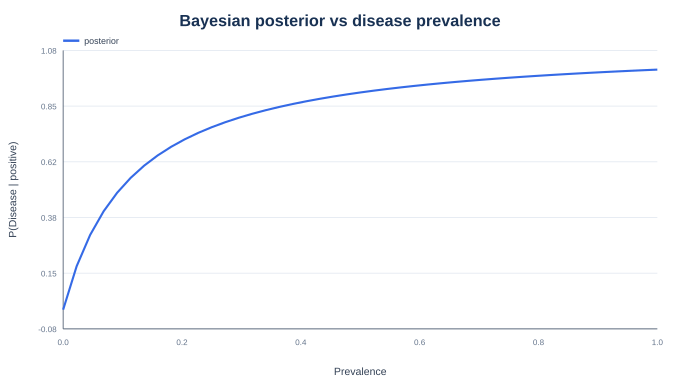

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bernoulli, binom, poisson, uniform, norm

rng = np.random.default_rng(3)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
samples = [
    ("Bernoulli(p=.3)", bernoulli(.3).rvs(1200, random_state=rng), np.arange(2), bernoulli(.3)),
    ("Binomial(n=10,p=.4)", binom(10, .4).rvs(1200, random_state=rng), np.arange(11), binom(10, .4)),
    ("Poisson(λ=4)", poisson(4).rvs(1200, random_state=rng), np.arange(13), poisson(4)),
    ("Uniform(0,1)", uniform().rvs(1200, random_state=rng), None, uniform()),
    ("Gaussian(μ=0,σ=1)", norm().rvs(1200, random_state=rng), None, norm())
]
for ax, (name, data, support, dist) in zip(axes.flat, samples):
    if support is None:
        ax.hist(data, bins=30, density=True, alpha=.55, label="sample")
        x = np.linspace(min(data), max(data), 250)
        ax.plot(x, dist.pdf(x), color="crimson", label="PDF")
    else:
        counts = np.bincount(data.astype(int), minlength=len(support)) / len(data)
        ax.bar(support, counts, alpha=.55, label="sample")
        ax.plot(support, dist.pmf(support), "o-", color="crimson", label="PMF")
    ax.set_title(name); ax.legend(fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

prevalence, sensitivity, specificity = .01, .95, .90
false_positive_rate = 1 - specificity
posterior = sensitivity * prevalence / (
    sensitivity * prevalence + false_positive_rate * (1 - prevalence))
print(f"P(Disease | Positive) by Bayes' theorem: {posterior:.4%}")

n = 100_000
disease = rng.random(n) < prevalence
positive = np.where(disease, rng.random(n) < sensitivity,
                    rng.random(n) < false_positive_rate)
empirical = disease[positive].mean()
print(f"Empirical P(Disease | Positive): {empirical:.4%} ({positive.sum()} positive tests)")

prevalences = np.linspace(.001, .20, 250)
posteriors = sensitivity * prevalences / (
    sensitivity * prevalences + false_positive_rate * (1 - prevalences))
plt.figure(figsize=(7, 4))
plt.plot(100*prevalences, 100*posteriors, lw=2)
plt.scatter([1], [100*posterior], color="crimson", label="1% prevalence")
plt.xlabel("Disease prevalence (%)"); plt.ylabel("P(Disease | Positive) (%)")
plt.title("Positive predictive value depends on prevalence")
plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.show()